In [1]:
import os
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier


In [2]:
# Carpeta del notebook nuevo y sus resultados.
PROJECT_DIR = Path.cwd()

# Datos
METADATA_DIR = Path(os.environ.get("FMA_METADATA_DIR", str(PROJECT_DIR / "fma_metadata")))
AUDIO_DIR = Path(os.environ.get("FMA_AUDIO_DIR", str(PROJECT_DIR / "fma_medium")))

RESULTS_DIR = PROJECT_DIR / "resultados"
RESULTS_DIR.mkdir(exist_ok=True)

FEATURES_FILE = RESULTS_DIR / "caracteristicas_basales.csv"

In [3]:
# Los ocho géneros seleccionados en la metodología
GENRES = [
    "Rock", "Electronic", "Experimental", "Hip-Hop",
    "Folk", "Instrumental", "Pop", "International"
]

SR = 22050                 # Muestras de audio por segundo.
DURATION = 30              # Segundos utilizados de cada pista.
N_FFT = 1024               # Tamaño de cada ventana de análisis.
HOP_LENGTH = 512           # Avance entre ventanas; deja 50 % de solapamiento.
N_MFCC = 13                # Coeficientes MFCC por ventana, incluido el 0.
ROLLOFF_PERCENT = 0.85     # Porcentaje de energía usado para el rolloff.
SEED = 42                 

RF_TREES = 100             
RF_MAX_DEPTH = 20          # Profundidad máxima de árboles.

XGB_TREES = 100            # Número de estimadores de XGBoost.
XGB_LEARNING_RATE = 0.1    # Tamaño de cada actualización del modelo.
XGB_MAX_DEPTH = 6          # Profundidad máxima de sus árboles.

# Valores que probará la búsqueda en rejilla de SVM.
SVM_C = [0.1, 1, 10, 100]
SVM_GAMMA = ["scale", 0.001, 0.01]

# Pistas con audio con errores.
BAD_IDS = {
    1486, 5574, 65753, 80391, 98558, 98559, 98560,
    98565, 98566, 98567, 98568, 98569, 98571, 99134,
    105247, 108924, 108925, 126981, 127336, 133297, 143992
}

FEATURES_FILE = RESULTS_DIR / "caracteristicas_basales.csv"
FEATURE_COLS = [f"mfcc_{i}" for i in range(N_MFCC)] + ["centroid", "rolloff", "zcr"]

In [4]:
#seleccion de pistas

tracks = pd.read_csv(METADATA_DIR / "tracks.csv", index_col=0, header=[0, 1])

selected = tracks.loc[
    tracks[("set", "subset")].isin(["small", "medium"])
    & tracks[("track", "genre_top")].isin(GENRES)
].drop(index=BAD_IDS, errors="ignore")

print("Pistas seleccionadas:", len(selected))
print(selected[("set", "split")].value_counts())
print(selected[("track", "genre_top")].value_counts())


Pistas seleccionadas: 22921
(set, split)
training      18293
test           2334
validation     2294
Name: count, dtype: int64
(track, genre_top)
Rock             7097
Electronic       6311
Experimental     2250
Hip-Hop          2192
Folk             1518
Instrumental     1349
Pop              1186
International    1018
Name: count, dtype: int64


# Extracción de 16 características
Cada audio se remuestrea a 22 050 Hz y se normaliza por su amplitud máxima. La media temporal de los 13 MFCC y la media de centroide, rolloff y ZCR forman un vector de 16 valores. El espectro usa ventanas Hamming de 1024 muestras con avance de 512

In [5]:
def extract_features(track_id):
    filename = f"{track_id:06d}"
    path = AUDIO_DIR / filename[:3] / f"{filename}.mp3"
    audio, _ = librosa.load(path, sr=SR, mono=True, duration=DURATION)

    if len(audio) < N_FFT:
        raise ValueError(f"Audio demasiado corto: {path}")
    audio = audio / max(np.max(np.abs(audio)), 1e-12)

    spectrum = np.abs(
        librosa.stft(audio, n_fft=N_FFT, hop_length=HOP_LENGTH, window="hamming")
    )
    mel = librosa.feature.melspectrogram(S=spectrum**2, sr=SR)
    mfcc = librosa.feature.mfcc(S=librosa.power_to_db(mel), n_mfcc=N_MFCC)

    return [
        *mfcc.mean(axis=1),
        librosa.feature.spectral_centroid(S=spectrum, sr=SR).mean(),
        librosa.feature.spectral_rolloff(
            S=spectrum**2, sr=SR, roll_percent=ROLLOFF_PERCENT
        ).mean(),
        librosa.feature.zero_crossing_rate(
            audio, frame_length=N_FFT, hop_length=HOP_LENGTH
        ).mean()
    ]

# Extracción y guardado
Se guardan bloques de 250 pistas. Si el proceso se interrumpe, al ejecutar de nuevo esta celda se continúa desde los IDs presentes en el CSV. Si cambias los parámetros de extracción, elimina primero resultados/caracteristicas_basales.csv para recalcular las características.

In [6]:
done = (
    set(pd.read_csv(FEATURES_FILE, usecols=["track_id"])["track_id"])
    if FEATURES_FILE.exists() else set()
)
rows = []
processed = len(done)
print(f"Procesadas: {processed}/{len(selected)}")

for track_id, track in selected.iterrows():
    if track_id in done:
        continue

    values = extract_features(track_id)
    rows.append({
        "track_id": track_id,
        "genre": track[("track", "genre_top")],
        "split": track[("set", "split")],
        **dict(zip(FEATURE_COLS, values))
    })

    if len(rows) == 250:
        pd.DataFrame(rows).to_csv(
            FEATURES_FILE, mode="a", header=not FEATURES_FILE.exists(), index=False
        )
        processed += len(rows)
        rows = []
        print(f"Procesadas: {processed}/{len(selected)}")

if rows:
    pd.DataFrame(rows).to_csv(
        FEATURES_FILE, mode="a", header=not FEATURES_FILE.exists(), index=False
    )

data = pd.read_csv(FEATURES_FILE).set_index("track_id").sort_index()
if set(data.index) != set(selected.index) or not data.index.is_unique or not np.isfinite(data[FEATURE_COLS]).all().all():
    raise ValueError("hay error")

print(f"Extracción completa: {len(data)} pistas y {len(FEATURE_COLS)} características")


Procesadas: 22921/22921
Extracción completa: 22921 pistas y 16 características


In [7]:
#Particiones y validación cruzada

X_train = data.loc[data["split"] == "training", FEATURE_COLS]
y_train = data.loc[data["split"] == "training", "genre"]
X_val = data.loc[data["split"] == "validation", FEATURE_COLS]
y_val = data.loc[data["split"] == "validation", "genre"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"accuracy": "accuracy", "f1_weighted": "f1_weighted"}

print("Training:", len(X_train), "| Validation:", len(X_val))

Training: 18293 | Validation: 2294


In [8]:
#Rnadom forest

rf = RandomForestClassifier(
    n_estimators=RF_TREES,
    max_depth=RF_MAX_DEPTH,
    criterion="gini",
    random_state=SEED
)

rf_cv = cross_validate(rf, X_train, y_train, cv=cv, scoring=scoring)
print("Accuracy CV:", rf_cv["test_accuracy"].mean())
print("F1 ponderado CV:", rf_cv["test_f1_weighted"].mean())
rf.fit(X_train, y_train)


Accuracy CV: 0.5406431799119915
F1 ponderado CV: 0.49975952925723865


,n_estimators,100
,criterion,'gini'
,max_depth,20
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


# SVM con escalado
Cse agrega StandardScaler antes de SVM porque los descriptores tienen escalas distintas. Ambos pasos se incluyen en Pipeline: en cada pliegue el escalador aprende solo con la parte de entrenamiento, evitando filtración de datos. La rejilla elige C y gamma según F1 ponderado.

In [9]:
from sklearn.pipeline import Pipeline

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf"))
])

svm_search = GridSearchCV(
    svm_pipeline,
    {"svc__C": SVM_C, "svc__gamma": SVM_GAMMA},
    cv=cv,
    scoring="f1_weighted"
)
svm_search.fit(X_train, y_train)

print("Mejores parámetros:", svm_search.best_params_)
print("F1 ponderado en la búsqueda CV:", svm_search.best_score_)


Mejores parámetros: {'svc__C': 10, 'svc__gamma': 'scale'}
F1 ponderado en la búsqueda CV: 0.5347369440523595


In [10]:
# XGBoost

encoder = LabelEncoder().fit(y_train)
y_train_encoded = encoder.transform(y_train)

xgb = XGBClassifier(
    n_estimators=XGB_TREES,
    learning_rate=XGB_LEARNING_RATE,
    max_depth=XGB_MAX_DEPTH,
    random_state=SEED
)

xgb_cv = cross_validate(xgb, X_train, y_train_encoded, cv=cv, scoring=scoring)
print("Accuracy CV:", xgb_cv["test_accuracy"].mean())
print("F1 ponderado CV:", xgb_cv["test_f1_weighted"].mean())
xgb.fit(X_train, y_train_encoded)


Accuracy CV: 0.5443062194808341
F1 ponderado CV: 0.5064959319278689


,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


# Resultados en validation
Los tres modelos predicen exactamente las mismas pistas. Se guardan las métricas y predicciones por ID, que servirán para la comparación posterior. La puntuación de búsqueda de SVM seleccionó parámetros en esos mismos pliegues, por lo que no se interpreta como una estimación independiente, los resultados en validation sí permiten una primera comparación.

,modelo,accuracy_validation,f1_ponderado_validation
0,Random Forest,0.5418,0.4879
1,SVM RBF,0.5484,0.5060
2,XGBoost,0.5310,0.4844


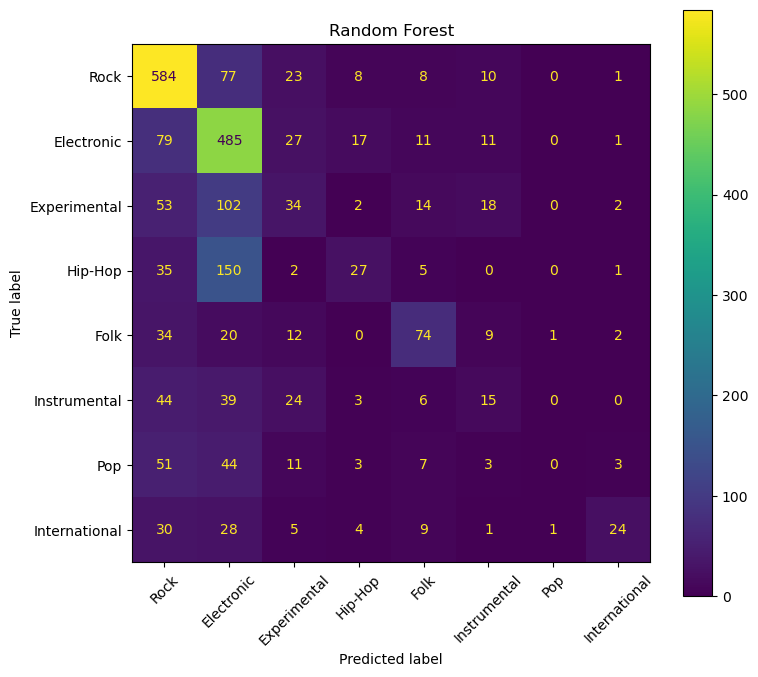

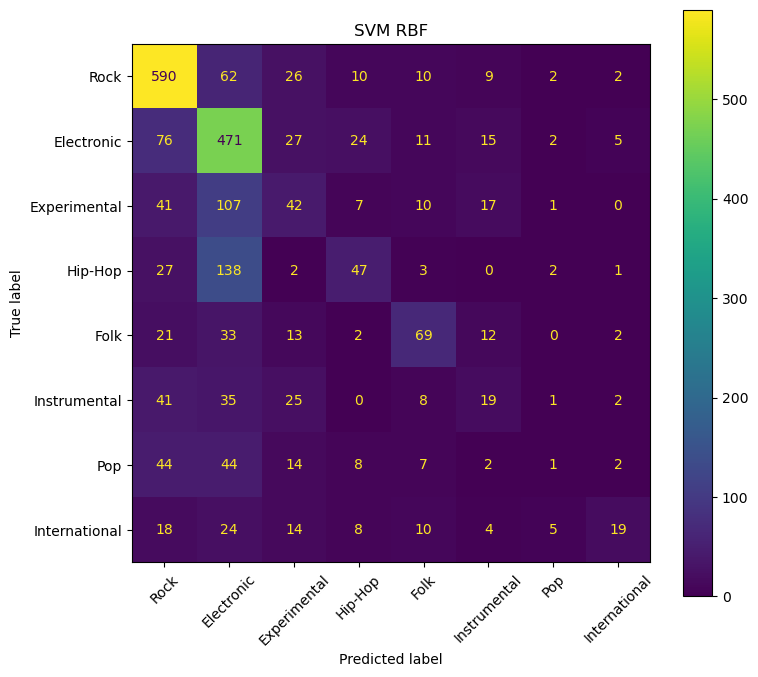

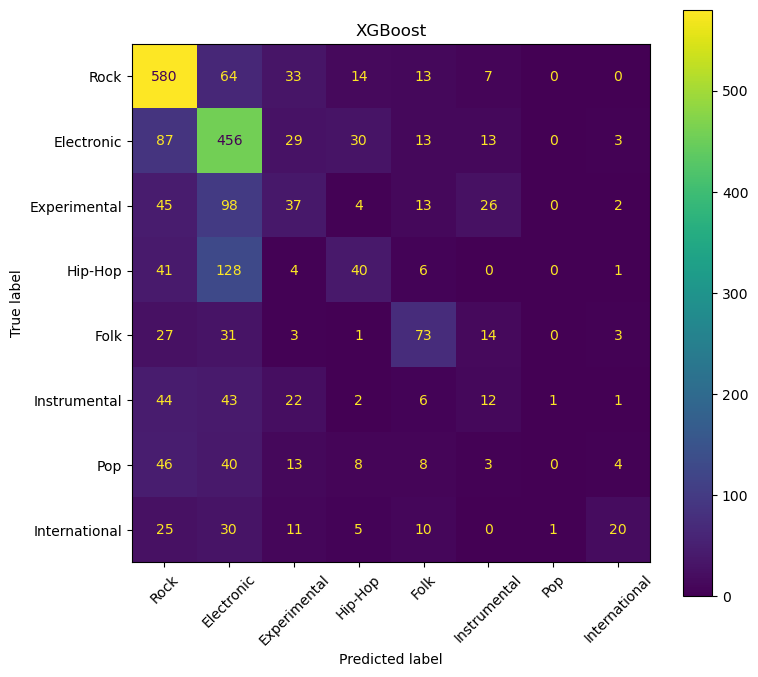

In [11]:
predictions = {
    "Random Forest": rf.predict(X_val),
    "SVM RBF": svm_search.predict(X_val),
    "XGBoost": encoder.inverse_transform(xgb.predict(X_val))
}

results = pd.DataFrame([
    {
        "modelo": name,
        "accuracy_validation": accuracy_score(y_val, pred),
        "f1_ponderado_validation": f1_score(y_val, pred, average="weighted")
    }
    for name, pred in predictions.items()
])
display(results.round(4))

validation_predictions = pd.DataFrame({
    "track_id": X_val.index,
    "genre_real": y_val.to_numpy(),
    **{name: pred for name, pred in predictions.items()}
})
results.to_csv(RESULTS_DIR / "basal_metricas_validation.csv", index=False)
validation_predictions.to_csv(RESULTS_DIR / "basal_predicciones_validation.csv", index=False)

for name, pred in predictions.items():
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay.from_predictions(
        y_val, pred, labels=GENRES, xticks_rotation=45, ax=ax, values_format="d"
    )
    ax.set_title(name)
    plt.tight_layout()
    plt.show()



## Segunda experimentación: atributos y parámetros

se pruban configuraciones

| Configuración | Atributos | Pesos RF/SVM | Árboles RF/XGBoost |
|---|---:|---|---:|
| A_original | 16 | No | 100 |
| B_atributos | 56 | No | 100 |
| C_pesos | 56 | Sí | 100 |
| D_arboles | 56 | Sí | 300 |

A-B evalúa el bloque de atributos nuevos; B-C evalúa los pesos; C-D evalúa el número de árboles. 
Son comparaciones entre configuraciones especificadas, no una búsqueda de todos los parámetros posibles.

In [12]:
# Extraer los 40 atributos adicionales
# Se procesan las mismas pistas y los mismos audios del basal
# El archivo se guarda por bloques para poder reanudar la extracción.

EXPERIMENT_FEATURES_FILE = RESULTS_DIR / "caracteristicas_acusticas_56.csv"

ADDED_COLS = (
    [f"mfcc_mean_{i}" for i in range(13, 20)]
    + [f"mfcc_std_{i}" for i in range(20)]
    + ["centroid_std"]
    + [f"chroma_mean_{i}" for i in range(12)]
)
ACOUSTIC_COLS = FEATURE_COLS + ADDED_COLS

def extract_added_features(track_id):
    filename = f"{track_id:06d}"
    path = AUDIO_DIR / filename[:3] / f"{filename}.mp3"

    audio, _ = librosa.load(path, sr=SR, mono=True, duration=DURATION)
    if len(audio) < N_FFT:
        raise ValueError(f"Audio demasiado corto: {path}")

    audio = audio / max(np.max(np.abs(audio)), 1e-12)
    spectrum = np.abs(
        librosa.stft(audio, n_fft=N_FFT, hop_length=HOP_LENGTH, window="hamming")
    )

    mel = librosa.feature.melspectrogram(S=spectrum**2, sr=SR)
    mfcc = librosa.feature.mfcc(S=librosa.power_to_db(mel), n_mfcc=20)
    centroid = librosa.feature.spectral_centroid(S=spectrum, sr=SR)
    chroma = librosa.feature.chroma_stft(
        S=spectrum**2, sr=SR, n_fft=N_FFT, hop_length=HOP_LENGTH
    )

    return [
        *mfcc.mean(axis=1)[13:],
        *mfcc.std(axis=1),
        centroid.std(),
        *chroma.mean(axis=1)
    ]

done = (
    set(pd.read_csv(EXPERIMENT_FEATURES_FILE, usecols=["track_id"])["track_id"])
    if EXPERIMENT_FEATURES_FILE.exists() else set()
)
rows = []

for number, track_id in enumerate(data.index, start=1):
    if track_id not in done:
        rows.append({
            "track_id": track_id,
            **data.loc[track_id, FEATURE_COLS].to_dict(),
            **dict(zip(ADDED_COLS, extract_added_features(track_id)))
        })

    if len(rows) == 250:
        pd.DataFrame(rows).to_csv(
            EXPERIMENT_FEATURES_FILE,
            mode="a",
            header=not EXPERIMENT_FEATURES_FILE.exists(),
            index=False
        )
        rows = []

    if number % 1000 == 0 or number == len(data):
        print(f"Pistas revisadas: {number}/{len(data)}")

if rows:
    pd.DataFrame(rows).to_csv(
        EXPERIMENT_FEATURES_FILE,
        mode="a",
        header=not EXPERIMENT_FEATURES_FILE.exists(),
        index=False
    )

Pistas revisadas: 1000/22921
Pistas revisadas: 2000/22921


Pistas revisadas: 3000/22921
Pistas revisadas: 4000/22921
Pistas revisadas: 5000/22921
Pistas revisadas: 6000/22921


Pistas revisadas: 7000/22921
Pistas revisadas: 8000/22921
Pistas revisadas: 9000/22921


Pistas revisadas: 10000/22921
Pistas revisadas: 11000/22921
Pistas revisadas: 12000/22921
Pistas revisadas: 13000/22921
Pistas revisadas: 14000/22921
Pistas revisadas: 15000/22921


Pistas revisadas: 16000/22921


Pistas revisadas: 17000/22921


Pistas revisadas: 18000/22921


Pistas revisadas: 19000/22921
Pistas revisadas: 20000/22921
Pistas revisadas: 21000/22921
Pistas revisadas: 22000/22921
Pistas revisadas: 22921/22921


In [13]:
# Comprobar que la ampliación conserva el basal
# Se verifica que están todos los `track_id` 
# que no hay valores inválidos y que los 16 atributos iniciales coinciden con los del primer experimento

acoustic_56 = pd.read_csv(
    EXPERIMENT_FEATURES_FILE
).set_index("track_id").sort_index()

if len(ADDED_COLS) != 40 or len(ACOUSTIC_COLS) != 56:
    raise ValueError("El número de atributos no es 16 + 40.")

if not acoustic_56.index.is_unique or not acoustic_56.index.equals(data.index):
    raise ValueError("Los track_id no coinciden con los del basal.")

if not np.isfinite(acoustic_56[ACOUSTIC_COLS].to_numpy()).all():
    raise ValueError("Hay valores no finitos en los atributos.")

if not np.allclose(
    acoustic_56[FEATURE_COLS].to_numpy(),
    data[FEATURE_COLS].to_numpy()
):
    raise ValueError("Los primeros 16 atributos no coinciden con el basal.")

X56_train = acoustic_56.loc[X_train.index, ACOUSTIC_COLS]
print("Training:", X_train.shape, "→", X56_train.shape)

Training: (18293, 16) → (18293, 56)


In [14]:
#Validación cruzada de las cuatro configuraciones
#Se usan los cinco pliegues ya definidos en `training` y el F1 ponderado de la metodología
#La configuración A reutiliza los resultados que calculó el basal
from sklearn.model_selection import cross_val_score

cv_rows = [
    {
        "configuracion": "A_original",
        "modelo": "Random Forest",
        "f1_cv": rf_cv["test_f1_weighted"].mean()
    },
    {
        "configuracion": "A_original",
        "modelo": "SVM RBF",
        "f1_cv": svm_search.best_score_
    },
    {
        "configuracion": "A_original",
        "modelo": "XGBoost",
        "f1_cv": xgb_cv["test_f1_weighted"].mean()
    }
]

configurations = [
    ("B_atributos", X56_train, None, 100),
    ("C_pesos", X56_train, "balanced", 100),
    ("D_arboles", X56_train, "balanced", 300)
]

for name, X, weight, trees in configurations:
    forest = RandomForestClassifier(
        n_estimators=trees,
        max_depth=20,
        criterion="gini",
        class_weight=weight,
        random_state=SEED
    )
    rf_score = cross_val_score(
        forest, X, y_train, cv=cv, scoring="f1_weighted"
    ).mean()

    search = GridSearchCV(
        Pipeline([
            ("scaler", StandardScaler()),
            ("svc", SVC(kernel="rbf"))
        ]),
        {
            "svc__C": SVM_C,
            "svc__gamma": SVM_GAMMA,
            "svc__class_weight": [weight]
        },
        cv=cv,
        scoring="f1_weighted",
        refit=False
    )
    search.fit(X, y_train)

    boost = XGBClassifier(
        n_estimators=trees,
        learning_rate=0.1,
        max_depth=6,
        random_state=SEED
    )
    xgb_score = cross_val_score(
        boost, X, encoder.transform(y_train),
        cv=cv, scoring="f1_weighted"
    ).mean()

    cv_rows.extend([
        {"configuracion": name, "modelo": "Random Forest", "f1_cv": rf_score},
        {
            "configuracion": name,
            "modelo": "SVM RBF",
            "f1_cv": search.best_score_,
            "C": search.best_params_["svc__C"],
            "gamma": search.best_params_["svc__gamma"]
        },
        {"configuracion": name, "modelo": "XGBoost", "f1_cv": xgb_score}
    ])

basal_experiment = pd.DataFrame(cv_rows)

display(
    basal_experiment.pivot(
        index="configuracion", columns="modelo", values="f1_cv"
    ).round(4)
)

basal_experiment.to_csv(
    RESULTS_DIR / "basal_experimento_cv.csv", index=False
)

modelo,Random Forest,SVM RBF,XGBoost
configuracion,,,
A_original,0.4998,0.5347,0.5065
B_atributos,0.5587,0.6131,0.5860
C_pesos,0.5530,0.6072,0.5860
D_arboles,0.5564,0.6072,0.5951


## Prueba: 300 árboles sin pesos

Con 56 atributos, los pesos no mejoraron el F1 de RF ni SVM en el basal, mientras que 300 estimadores mejoraron XGBoost. Se compara B (100 árboles, sin pesos) con E (300 árboles, sin pesos) usando los mismos cinco pliegues.

SVM es idéntico en B y E: se calcula una vez para registrar también su accuracy. La selección de C y gamma sigue usando F1 ponderado.

In [15]:
metrics = {"accuracy": "accuracy", "f1": "f1_weighted"}
last_rows = []

for config, trees in [("B_atributos", 100), ("E_sin_pesos_300", 300)]:
    models = {
        "Random Forest": RandomForestClassifier(
            n_estimators=trees,
            max_depth=20,
            criterion="gini",
            random_state=SEED
        ),
        "XGBoost": XGBClassifier(
            n_estimators=trees,
            learning_rate=0.1,
            max_depth=6,
            random_state=SEED
        )
    }

    for name, model in models.items():
        labels = y_train if name == "Random Forest" else y_train_encoded
        scores = cross_validate(
            model, X56_train, labels, cv=cv, scoring=metrics
        )

        for fold in range(5):
            last_rows.append({
                "configuracion": config,
                "modelo": name,
                "fold": fold + 1,
                "accuracy": scores["test_accuracy"][fold],
                "f1_ponderado": scores["test_f1"][fold]
            })

svm_last = GridSearchCV(
    Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel="rbf"))
    ]),
    {"svc__C": SVM_C, "svc__gamma": SVM_GAMMA},
    cv=cv,
    scoring=metrics,
    refit="f1"
)
svm_last.fit(X56_train, y_train)

best = svm_last.best_index_

for config in ("B_atributos", "E_sin_pesos_300"):
    for fold in range(5):
        last_rows.append({
            "configuracion": config,
            "modelo": "SVM RBF",
            "fold": fold + 1,
            "accuracy": svm_last.cv_results_[
                f"split{fold}_test_accuracy"
            ][best],
            "f1_ponderado": svm_last.cv_results_[
                f"split{fold}_test_f1"
            ][best]
        })

basal_last_folds = pd.DataFrame(last_rows)
basal_last = basal_last_folds.groupby(
    ["configuracion", "modelo"], as_index=False
)[["accuracy", "f1_ponderado"]].mean()

display(basal_last.round(4))
print("SVM B/E:", svm_last.best_params_)

basal_last_folds.to_csv(
    RESULTS_DIR / "basal_ultima_cv_folds.csv", index=False
)
basal_last.to_csv(
    RESULTS_DIR / "basal_ultima_cv.csv", index=False
)

,configuracion,modelo,accuracy,f1_ponderado
0,B_atributos,Random Forest,0.5984,0.5587
1,B_atributos,SVM RBF,0.6287,0.6131
2,B_atributos,XGBoost,0.6162,0.5860
3,E_sin_pesos_300,Random Forest,0.6018,0.5615
4,E_sin_pesos_300,SVM RBF,0.6287,0.6131
5,E_sin_pesos_300,XGBoost,0.6240,0.5951


SVM B/E: {'svc__C': 10, 'svc__gamma': 'scale'}
